In [2]:
import numpy as np
import joblib
import jax
import jax.numpy as jnp
from functools import partial
import builtins
from numpy.polynomial.chebyshev import chebvander
from joblib import Parallel, delayed
from tqdm import tqdm

# ==============================================================================
# 1. LOAD DATA & SHARED CONFIGURATION
# ==============================================================================
print("Loading preprocessed arrays...")
load_path = '/storage/scratch1/2/ashelestov3/preprocessed_4096_data.npz'
data = np.load(load_path)

U_raw = data['U']
V_raw = data['V']
P_raw = data['P']
B_raw = data['B']
W_raw = data['W']
x_raw = data['x']
y_raw = data['y']
t_raw = data['t']

# Grid Parameters
size_x, size_y = U_raw.shape[0], U_raw.shape[1]
Nt = U_raw.shape[2]
Lx, Ly = 4.0, 1.0

# Calculate grid spacing (dx) for filter sizing
dx = x_raw[1] - x_raw[0]
print(f"Grid spacing dx detected as: {dx}")

# ==============================================================================
# 2. DEFINE METHOD A: CHEBYSHEV / FFT FILTERING
# ==============================================================================
def method_A_setup(Ny_in, Nx_in, Lx, Ly, delta_A):
    # 1. Chebyshev Nodes
    y_cheb_desc = np.cos(np.pi * np.arange(Ny_in) / (Ny_in - 1))
    x_cheb = 0.5 * (y_cheb_desc + 1.0)
    perm = np.argsort(x_cheb)
    x_cheb_sorted = x_cheb[perm]

    # 2. Horizontal Filter (Gx)
    kx = np.fft.rfftfreq(Nx_in, d=Lx / Nx_in) * 2 * np.pi
    Gx = np.exp(-kx**2 * delta_A**2 / 24.0)[:, None]

    # 3. Vertical Smoothing Matrix (S)
    delta_scaled = delta_A / Ly
    xk = x_cheb_sorted[None, :]
    xj = x_cheb_sorted[:, None]
    G_mat = np.exp(-6.0 * ((xk - xj) ** 2) / (delta_scaled ** 2))
    w = np.sqrt(x_cheb_sorted * (1.0 - x_cheb_sorted)) * np.pi / x_cheb_sorted.size
    WG = w[None, :] * G_mat
    S = WG / WG.sum(axis=1, keepdims=True)
    
    return Gx, S, perm

def run_method_A(U, V, P, B, W, Gx, S, perm, Nx, Ny, Nt):
    # Output containers
    dtype_u = U.dtype
    u_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    v_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    p_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    b_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    w_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    
    tau_xx_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    tau_xy_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)
    tau_yy_A = np.empty((Nx, Ny, Nt), dtype=dtype_u)

    def chunked_matmul(Matrix, Field, n_chunks=4):
        Field_T = Field.T
        Result_T = np.empty_like(Field_T)
        chunk = (Matrix.shape[0] + n_chunks - 1) // n_chunks
        for i in range(n_chunks):
            s = i * chunk
            e = min(s + chunk, Matrix.shape[0])
            if s >= e: break
            Result_T[s:e] = Matrix[s:e] @ Field_T
        return Result_T.T

    def process_step(ti):
        # Load Permuted Frame
        u_i = U[:, perm, ti]
        v_i = V[:, perm, ti]
        p_i = P[:, perm, ti]
        b_i = B[:, perm, ti]
        w_i = W[:, perm, ti]

        # X-Filter (FFT)
        def fx(f):
            uh = np.fft.rfft(f, axis=0)
            m = min(uh.shape[0], Gx.shape[0])
            uh_out = np.zeros_like(uh)
            uh_out[:m] = uh[:m] * Gx[:m]
            return np.fft.irfft(uh_out, n=Nx, axis=0)

        ux, vx, px, bx, wx = fx(u_i), fx(v_i), fx(p_i), fx(b_i), fx(w_i)
        u2x, uvx, v2x = fx(u_i**2), fx(u_i*v_i), fx(v_i**2)

        # Y-Filter (Matrix S)
        uf = chunked_matmul(S, ux)
        vf = chunked_matmul(S, vx)
        pf = chunked_matmul(S, px)
        bf = chunked_matmul(S, bx)
        wf = chunked_matmul(S, wx)
        
        u2f = chunked_matmul(S, u2x)
        uvf = chunked_matmul(S, uvx)
        v2f = chunked_matmul(S, v2x)

        # Stresses
        txx = u2f - uf**2
        txy = uvf - uf * vf
        tyy = v2f - vf**2

        return ti, uf, vf, pf, bf, wf, txx, txy, tyy

    print("Running Method A (Chebyshev/FFT)...")
    res = Parallel(n_jobs=max(1, joblib.cpu_count() - 2))(
        delayed(process_step)(t) for t in tqdm(range(Nt))
    )

    for ti, u, v, p, b, w, txx, txy, tyy in res:
        u_A[..., ti] = u
        v_A[..., ti] = v
        p_A[..., ti] = p
        b_A[..., ti] = b
        w_A[..., ti] = w
        tau_xx_A[..., ti] = txx
        tau_xy_A[..., ti] = txy
        tau_yy_A[..., ti] = tyy
        
    return u_A, v_A, p_A, b_A, w_A, tau_xx_A, tau_xy_A, tau_yy_A

# ==============================================================================
# 3. DEFINE METHOD B: JAX GAUSSIAN FILTERING
# ==============================================================================

def method_B_setup():
    def _sigma_from_delta(delta):
        return delta / jnp.sqrt(12.0)

    def _trap_weights_nonuniform(x):
        dx = jnp.diff(x)
        w_mid = 0.5 * (dx[:-1] + dx[1:])
        w0 = 0.5 * dx[0]
        wn = 0.5 * dx[-1]
        return jnp.concatenate([jnp.array([w0]), w_mid, jnp.array([wn])])

    @partial(jax.jit, static_argnums=(4,))
    def _convolve1d_nonuniform_gaussian(arr, coord, delta, alpha, axis):
        sigma = _sigma_from_delta(delta)
        R = alpha * delta
        wq = _trap_weights_nonuniform(coord)
        a = jnp.moveaxis(arr, axis, 0)
        dists = coord[:, None] - coord[None, :]
        kernel = jnp.exp(-0.5 * (dists / sigma)**2) * (jnp.abs(dists) <= R)
        weighted_kernel = kernel * wq[None, :]
        weights = weighted_kernel / weighted_kernel.sum(axis=1, keepdims=True)
        out = jnp.tensordot(weights, a, axes=(1, 0))
        return jnp.moveaxis(out, 0, axis)

    def gaussian_filter_2d_time(field, x, y, delta, alpha):
        def step(f):
            f = f[..., None]
            f = _convolve1d_nonuniform_gaussian(f, x, delta, alpha, axis=0)
            f = _convolve1d_nonuniform_gaussian(f, y, delta, alpha, axis=1)
            return f[..., 0]
        return jax.vmap(step, in_axes=2, out_axes=2)(field)

    return gaussian_filter_2d_time

def get_trim_indices(coord, delta):
    valid = np.where((coord >= coord[0] + delta) & (coord <= coord[-1] - delta))[0]
    if len(valid) > 0:
        return valid[0], valid[-1] + 1
    return 0, len(coord)

# ==============================================================================
# 4. EXECUTION AND DIFFERENCING
# ==============================================================================

# --- SET FILTER SCALE ---
# Explicitly setting filter scale to 3 * dx for both
target_delta = 3.0 * dx
print(f"Using filter scale (delta) = {target_delta} for both methods.")

# --- Setup A ---
Gx, S, perm = method_A_setup(size_y, size_x, Lx, Ly, delta_A=target_delta)

# Run A
u_A, v_A, p_A, b_A, w_A, txx_A, txy_A, tyy_A = run_method_A(
    U_raw, V_raw, P_raw, B_raw, W_raw, Gx, S, perm, size_x, size_y, Nt
)

# --- Setup B ---
alpha_B = 3
filter_B_fn = method_B_setup()

print("Running Method B (JAX)...")
# Convert to JAX
u_j = jnp.array(U_raw)
v_j = jnp.array(V_raw)
p_j = jnp.array(P_raw)
b_j = jnp.array(B_raw)
w_j = jnp.array(W_raw)
x_j = jnp.array(x_raw)
y_j = jnp.array(y_raw)

# Filter Primaries (using target_delta)
u_B = np.array(filter_B_fn(u_j, x_j, y_j, target_delta, alpha_B))
v_B = np.array(filter_B_fn(v_j, x_j, y_j, target_delta, alpha_B))
p_B = np.array(filter_B_fn(p_j, x_j, y_j, target_delta, alpha_B))
b_B = np.array(filter_B_fn(b_j, x_j, y_j, target_delta, alpha_B))
w_B = np.array(filter_B_fn(w_j, x_j, y_j, target_delta, alpha_B))

# Calculate Stresses B
uu_B = np.array(filter_B_fn(u_j**2, x_j, y_j, target_delta, alpha_B))
vv_B = np.array(filter_B_fn(v_j**2, x_j, y_j, target_delta, alpha_B))
uv_B = np.array(filter_B_fn(u_j*v_j, x_j, y_j, target_delta, alpha_B))

txx_B = uu_B - u_B**2
tyy_B = vv_B - v_B**2
txy_B = uv_B - u_B * v_B

# --- ALIGNMENT & DIFFERENCE ---
print("Computing Difference (Method A - Method B)...")

# 1. Determine trim indices used by Method B (based on target_delta)
sx_start, sx_end = get_trim_indices(x_raw, target_delta)
sy_start, sy_end = get_trim_indices(y_raw, target_delta)

# 2. Update Coordinate Arrays for Plotting
x = x_raw[sx_start:sx_end]
y = y_raw[sy_start:sy_end]

# 3. Slice Method A and B to the valid inner region
def trim(arr): return arr[sx_start:sx_end, sy_start:sy_end, :]

# Flip A if necessary (assuming A is Ascending Y and input might be Descending)
if y_raw[0] > y_raw[-1]: 
    def flip_y(arr): return arr[:, ::-1, :]
    u_A = flip_y(u_A); v_A = flip_y(v_A); p_A = flip_y(p_A); b_A = flip_y(b_A); w_A = flip_y(w_A)
    txx_A = flip_y(txx_A); txy_A = flip_y(txy_A); tyy_A = flip_y(tyy_A)

# Compute Diff
u_filt = trim(u_A) - trim(u_B)
v_filt = trim(v_A) - trim(v_B)
p_filt = trim(p_A) - trim(p_B)
b_filt = trim(b_A) - trim(b_B)
w_filt = trim(w_A) - trim(w_B)

tau_xx = trim(txx_A) - trim(txx_B)
tau_xy = trim(txy_A) - trim(txy_B)
tau_yy = trim(tyy_A) - trim(tyy_B)

# Stack for compatibility with plotting cells
u_bar = np.stack([u_filt, v_filt], axis=3)
row1 = np.stack([tau_xx, tau_xy], axis=3)
row2 = np.stack([tau_xy, tau_yy], axis=3)
tau = np.stack([row1, row2], axis=4)

print(f"Difference calculation complete.")
print(f"Final Shape: {u_filt.shape}")

Loading preprocessed arrays...
Grid spacing dx detected as: 0.0009765625
Using filter scale (delta) = 0.0029296875 for both methods.
Running Method A (Chebyshev/FFT)...


100%|██████████| 286/286 [00:21<00:00, 13.13it/s] 


Running Method B (JAX)...
Computing Difference (Method A - Method B)...
Difference calculation complete.
Final Shape: (4090, 1430, 286)


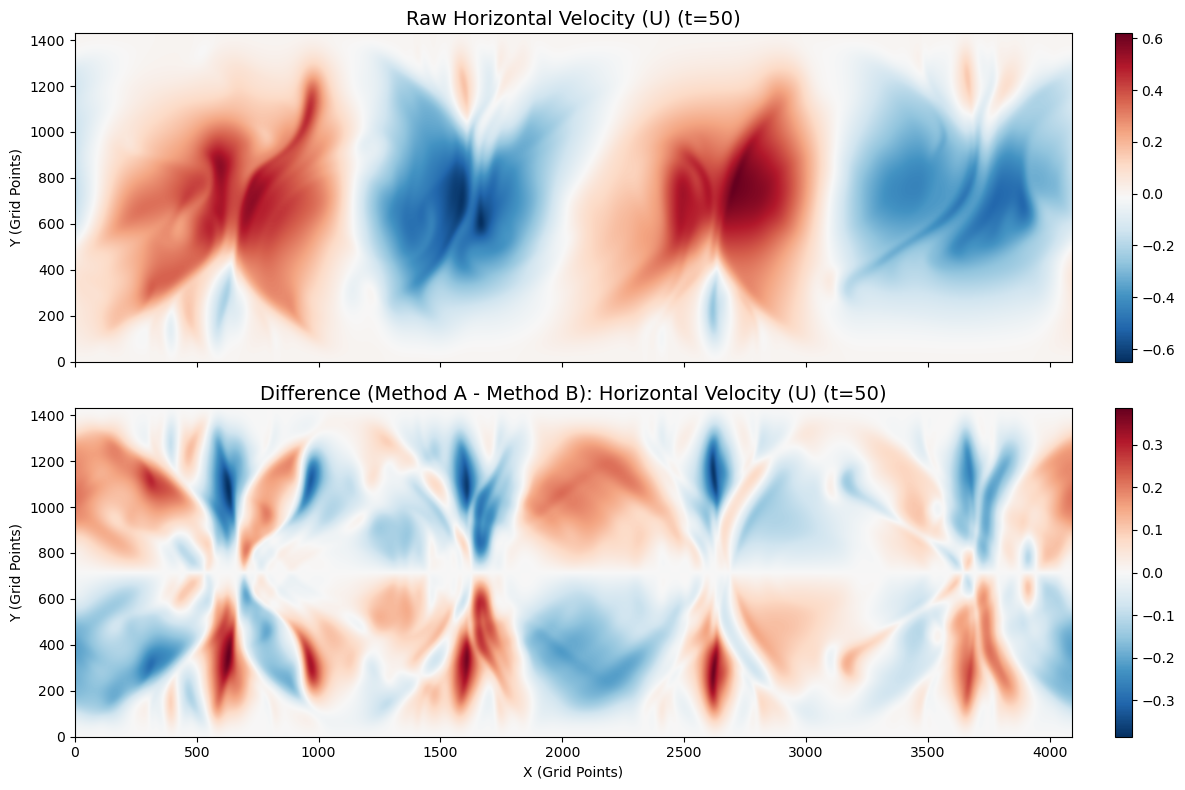

Zooming in on a small section...


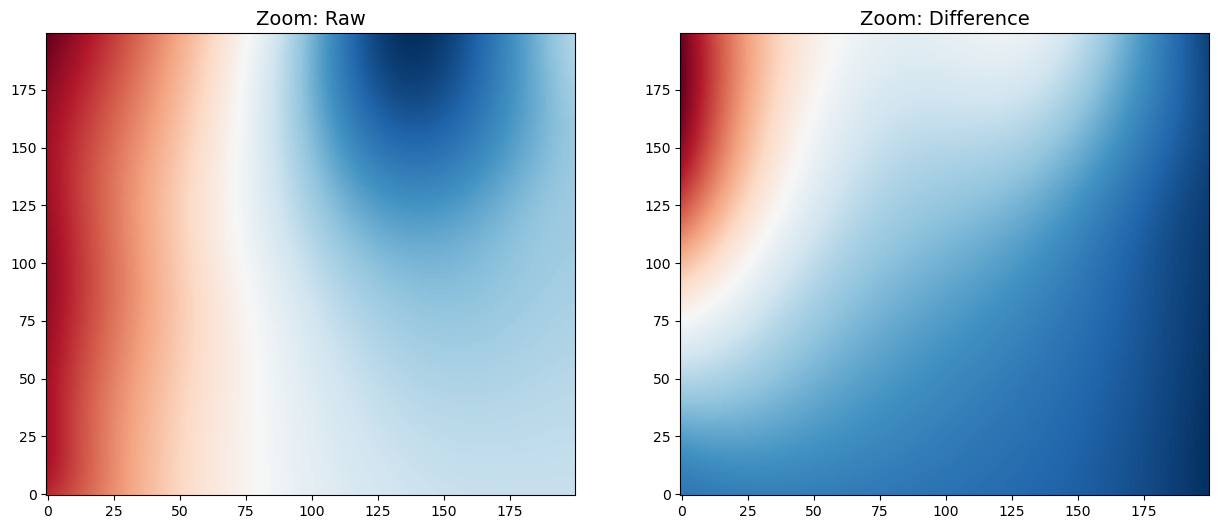

In [4]:
import matplotlib.pyplot as plt

# === Parameters ===
field_name = 'u'      # Choose: 'u', 'v', 'p', 'b', or 'w'
time_step_idx = 50    # Choose a timestep to visualize
cmap = 'RdBu_r'       # Colormap

# === Select Data ===
# Note: We slice the raw data to match the trimmed 'filt' (difference) arrays
# using the trim indices (sx_start, sx_end, etc.) from the calculation step.

if field_name == 'u':
    # Slice raw data to match the valid domain of the difference array
    raw_data = U_raw[sx_start:sx_end, sy_start:sy_end, time_step_idx]
    # u_filt is already the computed difference (Method A - Method B)
    filt_data = u_filt[:, :, time_step_idx] 
    title_txt = "Horizontal Velocity (U)"
elif field_name == 'v':
    raw_data = V_raw[sx_start:sx_end, sy_start:sy_end, time_step_idx]
    filt_data = v_filt[:, :, time_step_idx]
    title_txt = "Vertical Velocity (V)"
elif field_name == 'b':
    raw_data = B_raw[sx_start:sx_end, sy_start:sy_end, time_step_idx]
    filt_data = b_filt[:, :, time_step_idx]
    title_txt = "Buoyancy (B)"
elif field_name == 'p':
    raw_data = P_raw[sx_start:sx_end, sy_start:sy_end, time_step_idx]
    filt_data = p_filt[:, :, time_step_idx]
    title_txt = "Pressure (P)"
elif field_name == 'w':
    raw_data = W_raw[sx_start:sx_end, sy_start:sy_end, time_step_idx]
    filt_data = w_filt[:, :, time_step_idx]
    title_txt = "Vorticity (W)"

# === Plotting ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Raw
# Transpose (.T) so X is horizontal, Y is vertical
im1 = axes[0].imshow(raw_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title(f"Raw {title_txt} (t={time_step_idx})", fontsize=14)
axes[0].set_ylabel("Y (Grid Points)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Plot Difference
im2 = axes[1].imshow(filt_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title(f"Difference (Method A - Method B): {title_txt} (t={time_step_idx})", fontsize=14)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# === Optional: Zoom in ===
print("Zooming in on a small section...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Define zoom slice (ensure indices are within trimmed bounds)
ys, ye = 100, 300   # Y-slice
xs, xe = 1000, 1200 # X-slice

im3 = axes[0].imshow(raw_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title("Zoom: Raw", fontsize=14)

im4 = axes[1].imshow(filt_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title("Zoom: Difference", fontsize=14)

plt.show()

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np # Needed for array manipulation, e.g., range

# --- 1. Animation Setup and Parameters ---
FIELD_NAME = 'w'         # Choose: 'u', 'v', 'p', 'b', or 'w'
CMAP = 'RdBu_r'          # Colormap
SAVE_PATH = '/storage/scratch1/2/ashelestov3/anim/animated_fields.gif'
FPS = 10                 # Frames per second for the final GIF
INTERVAL_MS = dt # Delay in ms between frames (100ms for 10 FPS)
DPI_SETTING = 300

# --- 2. Data Initialization (Assuming your data is already loaded) ---
# NOTE: Replace 'W' and 'w_filt' with your actual loaded data arrays.
# I'm using placeholder data that mimics the structure: (X, Y, Time)
# Total number of time steps will be N_FRAMES
N_FRAMES = 286 # Adjust this based on the size of your time dimension
X_SIZE, Y_SIZE = 4096, 1536

# --- Placeholder Data (Replace with your actual loaded data) ---
# Assuming these are loaded from your .npz file (e.g., W = data['W'])
'''try:
    # If W, w_filt, and perm are not defined, create placeholders
    W = np.random.rand(X_SIZE, Y_SIZE, N_FRAMES)
    w_filt = np.sin(W)
    perm = np.arange(Y_SIZE) # A simple permutation array if needed
except NameError:
    print("WARNING: Data arrays (W, w_filt, perm) not found. Using placeholder data.")
    W = np.random.rand(X_SIZE, Y_SIZE, N_FRAMES)
    w_filt = np.sin(W)''
    perm = np.arange(Y_SIZE)'''
# -------------------------------------------------------------------
print(W.shape)
# Set Field and Title based on the selection
if FIELD_NAME == 'w':
    DATA_RAW = W
    DATA_FILT = w_filt
    TITLE_TXT = "Vorticity (W)"
# Add other 'elif' conditions here for 'u', 'v', etc., if you change FIELD_NAME
# For this example, we assume FIELD_NAME='w' is used.

# --- 3. Plotting Setup ---
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Determine the global min/max for the colorbar to keep it constant across frames
# This is crucial for a meaningful animation
v_min = min(np.min(DATA_RAW), np.min(DATA_FILT))
v_max = max(np.max(DATA_RAW), np.max(DATA_FILT))

# Initialize the first frame (time_step_idx = 0)
initial_raw_data = DATA_RAW[:, :, 0]
initial_filt_data = DATA_FILT[:, :, 0]

# Initialize Raw Plot
im1 = axes[0].imshow(
    initial_raw_data.T, 
    origin='lower', 
    cmap=CMAP, 
    aspect='auto', 
    vmin=v_min, 
    vmax=v_max
)
axes[0].set_ylabel("Y (Grid Points)")
cbar1 = plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
title1 = axes[0].set_title(f"Raw {TITLE_TXT} (t=0)", fontsize=14)

# Initialize Filtered Plot
im2 = axes[1].imshow(
    initial_filt_data.T, 
    origin='lower', 
    cmap=CMAP, 
    aspect='auto', 
    vmin=v_min, 
    vmax=v_max
)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
cbar2 = plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
title2 = axes[1].set_title(f"Filtered {TITLE_TXT} (t=0)", fontsize=14)

plt.tight_layout()

# --- 4. The Animation Function ---
def animate(i):
    """
    Updates the plot data for the i-th time step.
    'i' is the frame index (0 to N_FRAMES-1).
    """
    time_step_idx = i # The frame index is our time step

    # 1. Select the data for the current time step
    raw_frame_data = DATA_RAW[:, :, time_step_idx]
    filt_frame_data = DATA_FILT[:, :, time_step_idx]

    # 2. Update the image data (Note: We use .T to transpose)
    im1.set_data(raw_frame_data.T)
    im2.set_data(filt_frame_data.T)

    # 3. Update the titles
    title1.set_text(f"Raw {TITLE_TXT} (t={50+dt*time_step_idx})")
    title2.set_text(f"Filtered {TITLE_TXT} (t={50+dt*time_step_idx})")

    # Return the updated artists (plot elements)
    return im1, im2, title1, title2

# --- 5. Create and Save the Animation ---
print(f"Creating animation with {N_FRAMES} frames...")
anim = FuncAnimation(
    fig, 
    animate, 
    frames=N_FRAMES, 
    interval=INTERVAL_MS, 
    blit=True, 
    repeat=False # Set to True to loop
)

print(f"Saving animation to {SAVE_PATH} (FPS: {FPS})...")

try:
    # Requires 'pillow' or 'ffmpeg' to be installed. 'pillow' is best for GIF.
    anim.save(
        SAVE_PATH, 
        writer='pillow', 
        fps=FPS,
        dpi=DPI_SETTING
    )
    print("✅ Animation saved successfully!")
except Exception as e:
    print(f"❌ Error during saving: {e}")
    print("Ensure you have the 'pillow' library installed: `pip install pillow`")

plt.close(fig) # Close the figure to prevent displaying it in a window

In [ ]:
print(dx, dy)
# Calculate dx/dy from the actual new coordinate arrays
dx = x[1] - x[0]
dy = y[1] - y[0]
print(f"Updated dx: {dx}, dy: {dy}")

NameError: name 'Nx_out' is not defined

In [30]:
#%%prun # profiling
#print(P.shape)
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) #?
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
Tobs = Observable(string='T', rank=2, can_commute_indices = True, antisymmetric = False)
observables = [uobs, bobs, pobs, zobs, wobs, Tobs]#bobszobs

z = np.full(b_filt.shape, 1)
x = np.full(b_filt.shape, 0)
unit_vect = np.concatenate([x[:, :, :, np.newaxis], z[:, :, :, np.newaxis]], axis=3)
data_dict = {'u' : u_bar, 'b' : b_filt, 'p' : p_filt, 'z̄' : unit_vect, 'w' : w_filt, 'T' : tau}
print(u_filt.shape)
# fix random seed
np.random.seed(1)

world_size = np.array(p_filt.shape)
pad = 0

# fix random seed
np.random.seed(1)

dxs = [dx, dy, dt]

# initial setup of dataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())
                #irreps=(0, 1, 2))

# initialize libraries, domains, and weights
#srd.make_libraries(max_complexity=4, max_observables=3)
srd.make_libraries(max_complexity=3)
for irrep in srd.irreps:
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Logical cores (including hyperthreading)
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")
Ndomainz = len(srd.libs[srd.irreps[1]].terms)*10
num_processorz = num_cores - 4
Ndomainz_rounded = num_processorz * round(Ndomainz / num_processorz)
print(len(srd.libs[srd.irreps[1]].terms))
print(num_processorz)
print(Ndomainz_rounded)
dom_width = 64 #scale for res
dom_time = 40*200//236 #previously 20 (without interpolation)
pad = 0
srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time) # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)  # or whatever number of cores you want
'''
dom_width = 64 #previously 64 - smaller world size -> smaller domain??
dom_time = 20 #previously 20 (without interpolation)
print(len(srd.libs[srd.irreps[3]].terms))
srd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)
#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=12, qmax=0)


print(Lt)
L = dom_width
T = dom_time
#print(NLt)
print(L, T)

srd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False)'''

(4086, 1400, 286)
Rank 0 : 74
Rank 1 : 79
Antisymmetric rank 2 : 24
Symmetric trace-free rank 2 : 40
Logical CPU cores available: 128
79
124
744


/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


'\ndom_width = 64 #previously 64 - smaller world size -> smaller domain??\ndom_time = 20 #previously 20 (without interpolation)\nprint(len(srd.libs[srd.irreps[3]].terms))\nsrd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)\n#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)\nsrd.make_weights(m=12, qmax=0)\n\n\nprint(Lt)\nL = dom_width\nT = dom_time\n#print(NLt)\nprint(L, T)\n\nsrd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices\nsrd.make_library_matrices(debug=False)'

SyntaxError: invalid character '·' (U+00B7) (2736440118.py, line 1)

In [32]:
lib3 = srd.libs[srd.irreps[0]]
for idx, term in enumerate(lib3.terms):
    if str(term) == "∂α u_α":#"∂t b": #"u_β · ∂β u_α"
        print(f"Found at index {idx}: {term}") 
print(srd.libs)

Found at index 56: ∂α u_α
{Rank 0: LibraryData(terms=[T_αα, T_αα · b, T_αα · p, T_αα · w, ∂t T_αα, b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · ∂α z̄_α, ∂α b · u_α, ∂α b · z̄_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α, p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · ∂α z̄_α, ∂α p · u_α, ∂α p · z̄_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p, u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · ∂α w, u_α · z̄_α, u_α · ∂t z̄_α, ∂α u_α, ∂α u_α · w, ∂t u_α · z̄_α, ∂t ∂α u_α, w, w · w, w · w · w, w · ∂t w, w · z̄_α · z̄_α, w · ∂α z̄_α, ∂α w · z̄_α, ∂α² w, ∂t w, ∂t² w, z̄_α · z̄_α, z̄_α · ∂t z̄_α, ∂α z̄_α, ∂t ∂α z̄_α], irrep=Rank 0, Q=array([[ 6.77769258e-04,  3.30666952e-04, -1.54817129e-04, ...,
         0.00000000e+00,  2.02245629e-07, -3.38813179e-21],
       [ 2.25975473

In [33]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,4):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 26 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
∂t b = 0 ; residual: 0.0008630094389638869

Number of Terms in inhomogenous regression:  2
b · ∂t b + -0.5150532142316807 · ∂t b = 0 ; residual: 9.249287873348587e-05

Number of Terms in inhomogenous regression:  3
b · ∂t b + -0.0006530295063944092 · b · ∂t w + -0.5160712673271783 · ∂t b = 0 ; residual: 8.910335664653723e-05



In [34]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 46 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
u_β · ∂β u_α = 0 ; residual: 0.16920364462356058

Number of Terms in inhomogenous regression:  2
-0.28396805328733704 · ∂α p + u_β · ∂β u_α = 0 ; residual: 0.12808324208403013

Number of Terms in inhomogenous regression:  3
-0.3215149685025071 · b · ∂α p + b · z̄_α + 0.21954390254055667 · u_β · ∂β u_α = 0 ; residual: 0.054237432690233366

Number of Terms in inhomogenous regression:  4
0.03288759592028118 · b · ∂α p + -0.10396801054517463 · b · z̄_α + ∂t p · u_α + -0.02177705294295306 · u_β · ∂β u_α = 0 ; residual: 0.0016410862233251539

Number of Terms in inhomogenous regression:  5
0.035103386520898366 · b · ∂α p + -0.11197082517512313 · b · z̄_α + ∂t p · u_α + -0.13864687858265445 · u_α · u_β · u_β + -0.022481073075577018 · u_β · ∂β u_α = 0 ; residual: 0.0016678226236455035



In [35]:
'''from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 11 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")'''
 

'from commons_identify_models import *\n\nimport copy\n\nlibs = srd.libs\n\nlib3 = libs[srd.irreps[1]]\n\nfor aaaa in range(1,6):\n\n    max_kk = 5\n\n    print("Number of Terms in inhomogenous regression: ", aaaa)\n\n    reg_opts_list = []\n\n    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold\n\n    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)\n\n    #init = Initializer(method=\'combinatorial\', start_k=2)\n\n    #init = Initializer(method=\'combinatorial\', start_k=9999)\n\n    init = Initializer(method=\'combinatorial\', start_k=max_kk)\n\n    #res = Residual(residual_type=\'fixed_column\', anchor_col=0)\n\n    #res = Residual(residual_type=\'dominant_balance\')\n\n    res = Residual(residual_type=\'matrix_relative\')\n\n    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)\n\n    thres = Threshold(threshold_type=\'jump\', gamma=1.5, delta=1e-6, 

In [36]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 56 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
∂α u_α = 0 ; residual: 0.0866191410280036

Number of Terms in inhomogenous regression:  2
b · ∂α u_α + -0.511228343208651 · ∂α u_α = 0 ; residual: 0.006775090630194439

Number of Terms in inhomogenous regression:  3
0.351371080366664 · b · b · w + b · ∂α u_α + -0.48616220621796885 · ∂α u_α = 0 ; residual: 0.0060784761860511495

Number of Terms in inhomogenous regression:  4
0.6275796629528206 · b · ∂α u_α + b · w + -0.32384350012939034 · ∂α u_α + -0.5279073755830963 · w · z̄_α · z̄_α = 0 ; residual: 0.002056639286915507

Number of Terms in inhomogenous regression:  5
0.5960743314079524 · b · ∂α u_α + b · w + -0.16839004229618512 · ∂t b · w + -0.30854727690861533 · ∂α u_α + -0.5302923347198761 · w = 0 ; residual: 0.0010513211231444703



In [37]:

libs = srd.libs
print(libs)
lib3 = libs[srd.irreps[3]]
 
 
reg_opts_list = []
 
# for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)
#init = Initializer(method='combinatorial', start_k=2)
#init = Initializer(method='combinatorial', start_k=9999)
init = Initializer(method='combinatorial', start_k=max_kk)
#res = Residual(residual_type='fixed_column', anchor_col=0)
res = Residual(residual_type='matrix_relative')
 
iterator = ModelIterator(max_k=2, backward_forward=True, max_passes=20)
thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=2)
#thres = Threshold(threshold_type='information', ic=AIC)
 
opts = {'scaler': scaler, 'initializer': init, 'residual': res,
        'model_iterator': iterator, 'threshold': thres}
opts['verbose'] = False
opts['inhomog'] = True
opts['inhomog_col'] = 0#25
 
reg_result = sparse_reg_bf(lib3.Q, **opts)
zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]
eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
print(eqn, "; residual:", reg_result.lambd)

{Rank 0: LibraryData(terms=[T_αα, T_αα · b, T_αα · p, T_αα · w, ∂t T_αα, b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · ∂α z̄_α, ∂α b · u_α, ∂α b · z̄_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α, p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · ∂α z̄_α, ∂α p · u_α, ∂α p · z̄_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p, u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · ∂α w, u_α · z̄_α, u_α · ∂t z̄_α, ∂α u_α, ∂α u_α · w, ∂t u_α · z̄_α, ∂t ∂α u_α, w, w · w, w · w · w, w · ∂t w, w · z̄_α · z̄_α, w · ∂α z̄_α, ∂α w · z̄_α, ∂α² w, ∂t w, ∂t² w, z̄_α · z̄_α, z̄_α · ∂t z̄_α, ∂α z̄_α, ∂t ∂α z̄_α], irrep=Rank 0, Q=array([[ 6.778e-04,  3.307e-04, -1.548e-04, ...,  0.000e+00,  2.022e-07,
        -3.388e-21],
       [ 2.260e-02,  1.100e-02,  1.001e-03, ...,  0.000e+00,  2.022e-07,
  

-0.6113347081220674 · T_αβ + T_αβ · b + 0.6992614215517904 · T_αβ · p + 0.0055824162399115305 · T_αβ · w + -5.7682491353682565e-08 · ∂α u_β · w = 0 ; residual: 0.0017855007458076767


Calculating Residuals...
Computing derivatives...
Calculation Complete.
Residual U - Mean: 1.198699, Max: 12.142370
Residual V - Mean: 3.680081, Max: 26.396995


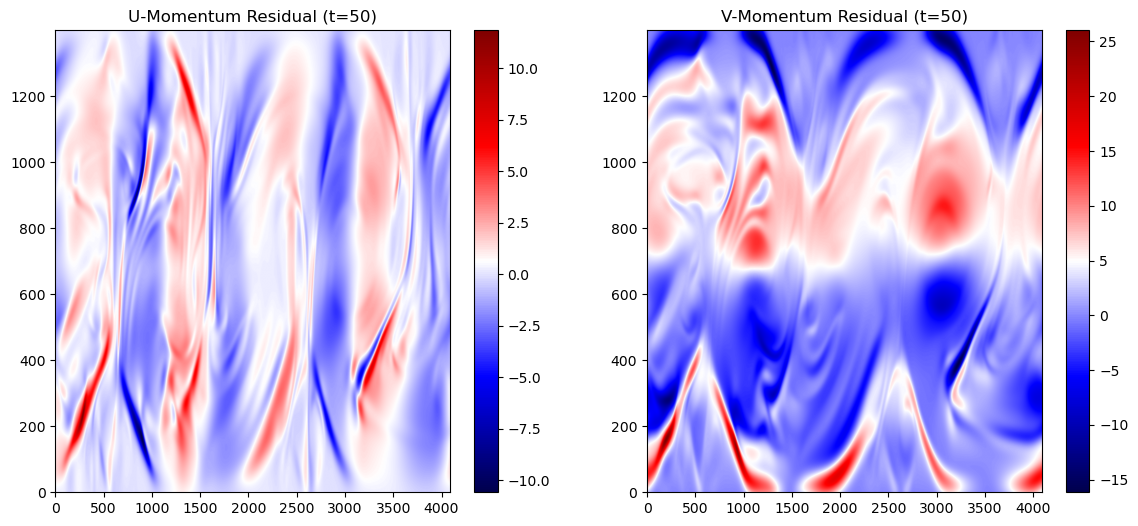

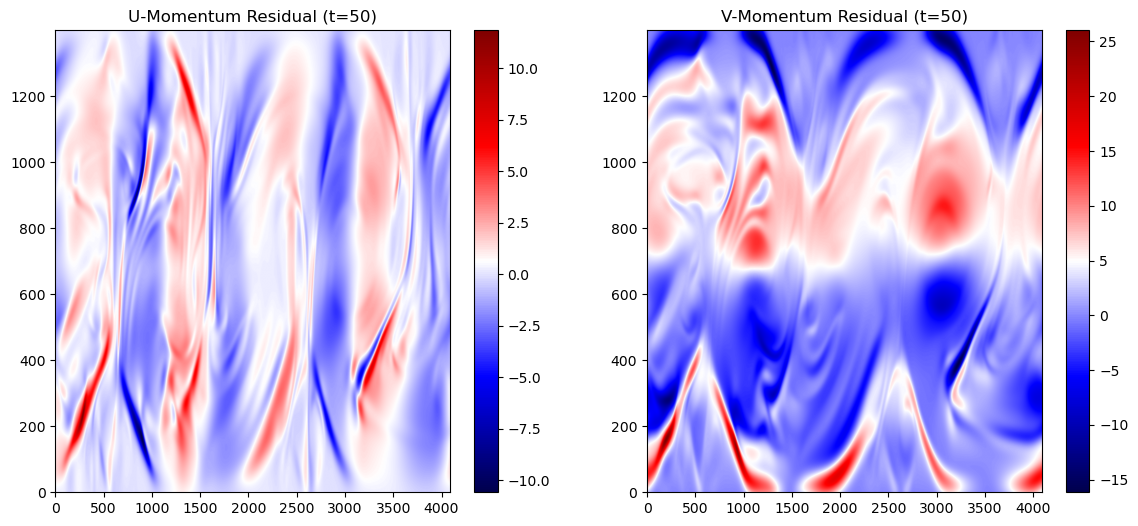

In [42]:
import numpy as np
import matplotlib.pyplot as plt
 
def compute_derivatives_and_residuals(u, v, p, b, tau, x, y, dt, kappa):
    """
    Computes terms of the momentum equations using np.gradient (central difference).
    Returns the residuals for U and V momentum equations.
    """
    print("Computing derivatives...")
    # Grid Spacing
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    # --- 1. Temporal Derivative (d/dt) ---
    # axis=2 is time
    u_t = np.gradient(u, dt, axis=2)
    v_t = np.gradient(v, dt, axis=2)
    # --- 2. Spatial Derivatives (First Order) ---
    # axis=0 is X, axis=1 is Y
    u_x = np.gradient(u, dx, axis=0)
    u_y = np.gradient(u, dy, axis=1)
    v_x = np.gradient(v, dx, axis=0)
    v_y = np.gradient(v, dy, axis=1)
    p_x = np.gradient(p, dx, axis=0)
    p_y = np.gradient(p, dy, axis=1)
    # --- 3. Viscous Terms (Laplacian) ---
    u_xx = np.gradient(u_x, dx, axis=0)
    u_yy = np.gradient(u_y, dy, axis=1)
    lap_u = u_xx + u_yy
    v_xx = np.gradient(v_x, dx, axis=0)
    v_yy = np.gradient(v_y, dy, axis=1)
    lap_v = v_xx + v_yy
    # --- 4. Subgrid Stress Divergence (div Tau) ---
    # tau shape: (Nx, Ny, Nt, 2, 2) -> (xx, xy; yx, yy)
    tau_xx = tau[..., 0, 0]
    tau_xy = tau[..., 0, 1]
    tau_yy = tau[..., 1, 1]
    # div(Tau)_x = d(tau_xx)/dx + d(tau_xy)/dy
    dtxx_dx = np.gradient(tau_xx, dx, axis=0)
    dtxy_dy = np.gradient(tau_xy, dy, axis=1)
    div_tau_x = dtxx_dx + dtxy_dy
    # div(Tau)_y = d(tau_xy)/dx + d(tau_yy)/dy
    dtxy_dx = np.gradient(tau_xy, dx, axis=0)
    dtyy_dy = np.gradient(tau_yy, dy, axis=1)
    div_tau_y = dtxy_dx + dtyy_dy
 
    # --- 5. Assemble Residuals ---
    # U-Momentum: du/dt + u*du/dx + v*du/dy = -dp/dx + nu*Lap(u) - div(Tau)_x
    # Residual = LHS - RHS
    # Note: If tau is defined as (Mean(uu) - Mean(u)Mean(u)), it sits on the RHS with a negative sign
    # as usually written in LES: d_t u_bar + div(u_bar u_bar) = ... - div(tau)
    adv_u = (u * u_x) + (v * u_y)
    # Res_U = Time + Advection + Pressure - Diffusion + Div(Tau)
    # Signs depend on how you move terms. Here we calculate:
    # Error = (Time + Advec) - (Pressure + Diffusion + Stress)
    # Check signs: Pressure is usually -dp/dx. Diffusion is +nu*Lap.
    # Standard Form: du/dt + u.grad(u) = -grad(p) + nu*Lap(u) - div(tau)
    # So: Res = (du/dt + u.grad(u)) - (-grad(p) + nu*Lap(u) - div(tau))
    Res_U = (u_t + adv_u) - (-p_x + kappa * lap_u - div_tau_x)
    # V-Momentum: dv/dt + u*dv/dx + v*dv/dy = -dp/dy + nu*Lap(v) + Buoyancy - div(Tau)_y
    # Buoyancy term usually +b (or T) in vertical direction
    adv_v = (u * v_x) + (v * v_y)
    Res_V = (v_t + adv_v) - (-p_y + kappa * lap_v + b - div_tau_y)
    return Res_U, Res_V
 
# --- EXECUTION ---

print("Calculating Residuals...")

# Unpack your variables
# u_bar shape is (Nx, Ny, Nt, 2)
_u = u_bar[..., 0]
_v = u_bar[..., 1]
_p = p_filt
_b = b_filt

# FIX: Use 'xp' and 'yp' (the actual filtered coordinates) instead of 'x' and 'y'
# 'x' and 'y' might have been overwritten by the SRDataset cell
res_u, res_v = compute_derivatives_and_residuals(_u, _v, _p, _b, tau, xp, yp, dt, kappa)

print("Calculation Complete.")
print(f"Residual U - Mean: {np.mean(np.abs(res_u)):.6f}, Max: {np.max(np.abs(res_u)):.6f}")
print(f"Residual V - Mean: {np.mean(np.abs(res_v)):.6f}, Max: {np.max(np.abs(res_v)):.6f}")

# --- PLOTTING ---
t_idx = 50

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])

im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])

plt.show()
 
# --- PLOTTING ---
# Visualize the error at a specific timestep
t_idx = 50
 
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
 
im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])
 
im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])
 
plt.show()

In [ ]:
# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()